# RAG Pipeline Benchmarking vs Ground Truth

Evaluates the T21 Research Assistant pipeline answers against human-curated ground truth answers.

**Input:** `input/AI_research_assistant_Sample_questions_revised_JIM_Negative_Ctrl_dt_03_12_2026.xlsx`
- `Original question` — question sent to the pipeline
- `Answer` — ground truth answer (human curated, semicolon-separated key points)
- `Citation` — optional citation

**Metrics computed per question:**
| Metric | Description |
|---|---|
| `semantic_sim` | Cosine similarity of llama-nemotron-embed-vl-1b-v2 embeddings (0–1) |
| `bertscore_p` | BERTScore Precision — mean max-similarity of each candidate sentence to any reference sentence |
| `bertscore_r` | BERTScore Recall — mean max-similarity of each reference sentence to any candidate sentence |
| `bertscore_f` | BERTScore F — harmonic mean of BERTScore Precision and Recall |

**BERTScore implementation:** Uses `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) embeddings at sentence granularity via the T21 `/embed_batch` API endpoint.
Two-pass sentence splitting: (1) split on `.!?` for prose; (2) split on `;` for GT key-point strings
that lack terminal punctuation. Precision and Recall are computed as the mean of maximum cosine
similarities across sentence pairs (mirrors the original BERTScore algorithm).

**Embeddings:** `nvidia/llama-nemotron-embed-vl-1b-v2` (2048-dim) via `/embed_batch` — device auto-detected: **GPU (CUDA) if available, otherwise CPU**. Device is reported in the config cell output.


## Cell 2 — Config

In [4]:
import os
from pathlib import Path
from dotenv import load_dotenv
import pandas as pd

# ── Paths — notebook lives in analysis/nbs/, so '..' resolves to analysis/ ───
_NB_DIR  = Path('..').resolve()           # analysis/
BASE_DIR = _NB_DIR                        # alias
load_dotenv(BASE_DIR / '.env')            # analysis/.env

EXCEL_PATH = BASE_DIR / 'input' / 'AI_research_assistant_Sample_questions_revised_JIM_Negative_Ctrl_dt_03_12_2026.xlsx'
OUTPUT_DIR = BASE_DIR / 'output' / 'batch_eval'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_XLSX = OUTPUT_DIR / 'benchmark_results_JIM.xlsx'
RESULTS_JSON = OUTPUT_DIR / 'benchmark_results_JIM.json'

# API endpoints — T21 RAG + Nemotron embed (reuse model already loaded in API)
T21_API_URL         = os.getenv('T21_API_URL',         'http://localhost:8698/answer')
T21_EMBED_BATCH_URL = os.getenv('T21_EMBED_BATCH_URL', 'http://localhost:8698/embed_batch')

OPENAI_KEY    = os.getenv('OPENAI_API_KEY', '')
ANTHROPIC_KEY = os.getenv('ANTHROPIC_API_KEY', '')

# Models for comparator responses
OPENAI_MODEL    = os.getenv('OPENAI_CHAT_MODEL',    'gpt-5.4')
ANTHROPIC_MODEL = os.getenv('ANTHROPIC_CHAT_MODEL', 'claude-sonnet-4-6')

# Ollama / Nemotron chat settings (remote cloud)
OLLAMA_API_KEY        = os.getenv('OLLAMA_API_KEY', '')
OLLAMA_NEMOTRON_MODEL = os.getenv('OLLAMA_NEMOTRON_MODEL', 'nemotron-3-super')
OLLAMA_BASE_URL       = os.getenv('OLLAMA_REMOTE_BASE_URL', 'https://ollama.com')

TOP_K     = 20
MAX_WORDS = 150    # hard ceiling for all model responses (~150-word summaries)

# Rate limit (T21 API calls only — no per-call sleep for embed, handled by API)
API_SLEEP = 1.5   # seconds between T21 /answer calls

# ── T21 RAG run configuration ─────────────────────────────────────────────────
# RERANK_ALPHA=0.2 is set in srv/.env and active in the running API container.
# section_mode="standard" → Results/Discussion/Methods/Conclusion only
#   (Abstract and Introduction are NOT retrieved — production default).
# These values are passed explicitly in call_t21() for reproducibility.
T21_RERANK_ALPHA  = 0.2          # confirmed live in API: curl /health → rerank_alpha: 0.2
T21_SECTION_MODE  = "standard"   # no Abstract / Introduction

# ── Device detection (local notebook environment) ─────────────────────────────
try:
    import torch
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    _gpu_name = torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'N/A'
except ImportError:
    DEVICE = 'cpu'
    _gpu_name = 'N/A (torch not installed)'

# ── API device detection (server-side embed model) ────────────────────────────
import requests as _req_cfg
_api_device = 'unknown'
try:
    _health = _req_cfg.get(T21_API_URL.replace('/answer', '/health'), timeout=10).json()
    _api_device = _health.get('config', {}).get('embed_device', 'unknown')
    if not _api_device or _api_device == 'unknown':
        # Infer from NEMOTRON_DEVICE env var if health doesn't expose it
        _api_device = os.getenv('NEMOTRON_DEVICE', '') or ('cuda' if DEVICE == 'cuda' else 'cpu')
except Exception as _e:
    _api_device = f'unreachable ({_e})'

assert OPENAI_KEY,    'OPENAI_API_KEY not set in .env'
assert ANTHROPIC_KEY, 'ANTHROPIC_API_KEY not set in .env'
print('Base dir          :', BASE_DIR)
print('Excel             :', EXCEL_PATH)
print('Output dir        :', OUTPUT_DIR)
print('T21 API           :', T21_API_URL)
print('T21 Embed batch   :', T21_EMBED_BATCH_URL, ' (llama-nemotron-embed-vl-1b-v2 2048-dim, server-side)')
print('OpenAI mdl        :', OPENAI_MODEL)
print('Claude mdl        :', ANTHROPIC_MODEL)
print('Nemotron chat mdl :', OLLAMA_NEMOTRON_MODEL, '(via', OLLAMA_BASE_URL + ')')
print('Results xlsx      :', RESULTS_XLSX)
print('top_k             :', TOP_K, '  max_words:', MAX_WORDS)
print(f'\n── T21 RAG Config ──────────────────────────────────────────────────────')
print(f'  RERANK_ALPHA    : {T21_RERANK_ALPHA}  (cross-encoder-heavy blend)')
print(f'  section_mode    : {T21_SECTION_MODE}  (Results/Discussion/Methods/Conclusion only)')
print(f'\n── Device ─────────────────────────────────────────────────────────────')
print(f'  Notebook env    : {DEVICE.upper()}' + (f'  ({_gpu_name})' if DEVICE == 'cuda' else ''))
print(f'  API embed model : {_api_device.upper()}  (server-side, controls /embed_batch)')


Base dir          : /path/to/project/T21_research_assistant_v6/analysis
Excel             : /path/to/project/T21_research_assistant_v6/analysis/input/AI_research_assistant_Sample_questions_revised_JIM_Negative_Ctrl_dt_03_12_2026.xlsx
Output dir        : /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval
T21 API           : http://localhost:8698/answer
T21 Embed batch   : http://localhost:8698/embed_batch  (llama-nemotron-embed-vl-1b-v2 2048-dim, server-side)
OpenAI mdl        : gpt-5.4
Claude mdl        : claude-sonnet-4-6
Nemotron chat mdl : nemotron-3-super (via https://ollama.com)
Results xlsx      : /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval/benchmark_results_JIM.xlsx
top_k             : 20   max_words: 150

── T21 RAG Config ──────────────────────────────────────────────────────
  RERANK_ALPHA    : 0.2  (cross-encoder-heavy blend)
  section_mode    : standard  (Results/Discussion/Methods/Conclusion only)

── Device ────────────────────

## Cell 3 — Imports

In [5]:
import json, time, re, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from tqdm.auto import tqdm
from openai import OpenAI
from anthropic import Anthropic
from ollama import Client as OllamaClient

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

openai_client    = OpenAI(api_key=OPENAI_KEY)
anthropic_client = Anthropic(api_key=ANTHROPIC_KEY)
ollama_client    = OllamaClient(
    host=OLLAMA_BASE_URL,
    headers={'Authorization': f'Bearer {OLLAMA_API_KEY}'},
)
print('Imports OK')
print(f'OpenAI   : {OPENAI_MODEL}')
print(f'Claude   : {ANTHROPIC_MODEL}')
print(f'Nemotron : {OLLAMA_NEMOTRON_MODEL}  @  {OLLAMA_BASE_URL}')


Imports OK
OpenAI   : gpt-5.4
Claude   : claude-sonnet-4-6
Nemotron : nemotron-3-super  @  https://ollama.com


In [ ]:
"""
Pre-run cleanup — run this cell before executing the benchmark pipeline.
  1. Clears the T21 API in-memory response cache so no stale answers bleed in.
  2. Verifies the Nemotron /embed_batch endpoint is alive.
  3. Releases Python kernel memory (gc.collect).
"""
import gc
import requests as _cleanup_req

_T21_BASE = T21_API_URL.replace('/answer', '')

# ── 1. Clear T21 API response cache ───────────────────────────────────────────
try:
    _r = _cleanup_req.post(f'{_T21_BASE}/cache/clear', timeout=10)
    _r.raise_for_status()
    print(f'API cache cleared  : {_r.json()}')
except Exception as _e:
    print(f'Cache clear skipped: {_e}')

# ── 2. Verify /embed_batch is alive (llama-nemotron-embed-vl-1b-v2 stays loaded in API) ─────────
try:
    _r2 = _cleanup_req.post(
        T21_EMBED_BATCH_URL,
        json={'texts': ['warmup'], 'mode': 'document'},
        timeout=30,
    )
    _r2.raise_for_status()
    _d2 = _r2.json()
    print(f'Embed endpoint OK  : dim={_d2["dim"]}  (nvidia/llama-nemotron-embed-vl-1b-v2)')
except Exception as _e2:
    print(f'Embed endpoint WARN: {_e2}')

# ── 3. Release Python kernel memory ───────────────────────────────────────────
gc.collect()
print('gc.collect() done  : kernel memory released')


## Cell 4 — Load benchmark questions & ground truth

In [6]:
df_bench = pd.read_excel(EXCEL_PATH, sheet_name='Questions_for_testing')
df_bench.columns = [c.strip() for c in df_bench.columns]

df_bench = df_bench.rename(columns={
    'Original question': 'question',
    'Answer'           : 'ground_truth',
    'Citation'         : 'citation',
    'CTRL_Type'        : 'ctrl_type',
})

# Keep all questions
df_bench = df_bench.dropna(subset=['question'])
df_bench['ground_truth'] = df_bench['ground_truth'].fillna('')
df_bench = df_bench.reset_index(drop=True)

# For negative controls the expected T21 response is the decline phrase.
# This becomes the ground truth so all models are evaluated against it.
_NEG_GT = (
    'No relevant information found in the available literature to answer this question.'
)
pos_mask = df_bench['ctrl_type'].str.strip().str.lower() == 'positive'
neg_mask = ~pos_mask
df_bench.loc[neg_mask & (df_bench['ground_truth'] == ''), 'ground_truth'] = _NEG_GT

print(f'Total questions     : {len(df_bench)}')
print(f'  Positive          : {pos_mask.sum()}')
print(f'  Negative (control): {neg_mask.sum()}')
print(f'\nNegative GT (expected decline):\n  "{_NEG_GT}"')
df_bench[['SLNo', 'ctrl_type', 'question', 'ground_truth']].head(8)


Total questions     : 22
  Positive          : 12
  Negative (control): 10

Negative GT (expected decline):
  "No relevant information found in the available literature to answer this question."


,SLNo,ctrl_type,question,ground_truth
0,Q1,Positive,Which clinical conditions are people with Down...,Individuals with Down syndrome are at high ris...
1,Q2,Positive,Which clinical conditions are people with Down...,Individuals with Down syndrome are at low risk...
2,Q3,Positive,Why do people with Down syndrome tend to have ...,"Four interferron receptors, IFNAR1, IFNAR2, IF..."
3,Q4,Positive,Why are people with Down syndrome at high risk...,Amyloid Precursor Protein (APP) is located on ...
4,Q5,Positive,Do individuals with Down syndrome have overact...,Autoimmune thyroid dysfunction is highly preva...
5,Q6,Positive,Which interferon receptors are triplicated in ...,Four of the six interferon receptors are found...
6,Q7,Positive,How is Stat1 signaling affected in Down syndro...,STAT1 signaling is generally increased due to ...
7,Q8,Positive,Which circulating immune cell is consistently ...,Individuals with Down syndrome have B cell lym...


## Cell 5 — Generate responses (T21 RAG, GPT, Claude)

In [7]:
import re as _re  # local alias used throughout this cell

# ── Constants ─────────────────────────────────────────────────────────────────
TOP_K_BASE    = TOP_K   # base retrieval count (from Cell 2)
TOP_K_MAX     = 30      # hard cap on dynamic boost
_GT_WC_FLOOR  = 80      # minimum target word count even if GT is very short

# ── Helper utilities (mirrors synthesizer_langchain + nb6) ───────────────────

_SENTENCE_END_RE    = _re.compile(r'[.!?]$')
_LIST_MARKER_RE     = _re.compile(r'^\d{1,2}[\.)]$')
_SPACE_BEFORE_PUNCT = _re.compile(r'\s+([.,;:!?])')
_ORPHAN_MARKER_RE   = _re.compile(r'(?:(?<=^)|(?<=\s))(?:[1-9]|1[0-2])(?=[.,;:!?](?:\s|$))')

def clean_response(text: str) -> str:
    text = str(text or '')
    text = _ORPHAN_MARKER_RE.sub('', text)
    text = _SPACE_BEFORE_PUNCT.sub(r'\1', text)
    text = _re.sub(r'\s{2,}', ' ', text)
    return text.strip()

def trim_to_sentences(text: str, max_words: int = MAX_WORDS) -> str:
    candidate = clean_response(text)
    if not candidate:
        return ''
    raw = _re.split(r'(?<=[.!?])\s+', candidate)
    complete = [s for s in raw
                if _SENTENCE_END_RE.search(s.strip()) and not _LIST_MARKER_RE.fullmatch(s.strip())]
    if not complete:
        return candidate
    result, count = [], 0
    for sent in complete:
        n = len(sent.split())
        if count + n > max_words:
            break
        result.append(sent)
        count += n
    return clean_response(' '.join(result) if result else complete[0])

def trim_to_gt_size(text: str, max_words: int, max_sents: int = 999) -> str:
    """Trim to at most max_words words AND max_sents sentences (whichever hits first).
    Used by Cell 5d _best_extract as a fallback — NOT called in the generation loop.
    All 4 models save full ~150-word outputs so Cell 5d has an equal-size pool.
    """
    candidate = clean_response(text)
    if not candidate:
        return ''
    raw = _re.split(r'(?<=[.!?])\s+', candidate)
    complete = [s for s in raw
                if _SENTENCE_END_RE.search(s.strip()) and not _LIST_MARKER_RE.fullmatch(s.strip())]
    if not complete:
        return candidate
    result, wc = [], 0
    for sent in complete:
        sw = len(sent.split())
        if wc + sw > max_words or len(result) >= max_sents:
            break
        result.append(sent)
        wc += sw
    return clean_response(' '.join(result) if result else complete[0])

def _count_sents(text: str) -> int:
    """Count complete sentences (≥3 words) — mirrors _split_sents from Cell 5d."""
    sents = [s.strip() for s in _re.split(r'(?<=[.!?])\s+', str(text).strip())
             if len(s.strip().split()) >= 3]
    return max(len(sents), 1)

def strip_quality_review(md: str) -> str:
    s = _re.sub(r'(?ims)^\s*#{1,6}\s*Quality\s+Review\s*\n.*?(?=^\s*#{1,6}\s*\S|\Z)', '', md)
    s = _re.sub(r'(?ims)^\s*Quality\s+Review\s*:?\s*\n.*?(?=^\s*#{1,6}\s*\S|\Z)', '', s)
    return _re.sub(r'\n{3,}', '\n\n', s).strip()

def extract_t21_answer(payload: dict) -> str:
    """Extract the # Summary section from a T21 API response.
    Strips all [PMCxxxxxxx:Section] citation markers for a fair text comparison.
    Returns the full cleaned prose (no word-count trimming applied here).
    """
    md = str(payload.get('markdown') or '')
    if md.strip():
        md = strip_quality_review(md)
        m = _re.search(r'#{1,2}\s*Summary[^\n]*\n(.*?)(?=\n#{1,2}\s|\Z)', md,
                       flags=_re.DOTALL | _re.IGNORECASE)
        txt = (m.group(1).strip() if m else md).strip()
        # Strip all citation markers so T21 text is citation-free for fair comparison
        txt = _re.sub(r'\s*\[{1,2}PMC\d{4,}:[A-Za-z0-9_-]+\]{1,2}(?:\([^)]+\))?', '', txt)
        txt = _re.sub(r'\[{1,2}PMC\d{4,}\]{1,2}(?:\([^)]+\))?', '', txt)
        return clean_response(txt)
    for k in ('answer', 'response', 'text', 'result'):
        v = str(payload.get(k) or '').strip()
        if v:
            return clean_response(v)
    return ''

# ── Dynamic top_k — mirrors synthesizer_langchain._get_dynamic_top_k ─────────

_COMPLEX_KEYWORDS = [
    'compare', 'versus', 'vs', 'difference', 'similar', 'contrast',
    'all', 'comprehensive', 'complete', 'overview', 'summarize',
    'how many', 'list', 'what are the', 'types of', 'categories',
    'mechanisms', 'pathways', 'treatments', 'therapies',
    'subgroups', 'subtypes', 'classification',
    'which', 'what conditions', 'what factors', 'what genes',
    'lower risk', 'higher risk', 'protective', 'risk factors',
    'associated with', 'related to', 'linked to',
]

def _get_dynamic_top_k(question: str, base_k: int = TOP_K_BASE, max_k: int = TOP_K_MAX) -> int:
    """Mirror of synthesizer_langchain._get_dynamic_top_k — same keyword list and boost rules."""
    q_lower = question.lower()
    boost = 0
    for kw in _COMPLEX_KEYWORDS:
        if kw in q_lower:
            boost = 5
            break
    if len(question) > 100:
        boost = max(boost, 3)
    if ' and ' in q_lower and len(question) > 50:
        boost = max(boost, 4)
    return min(base_k + boost, max_k)

# ── GT-length-adaptive prose system prompt (words + sentences) ───────────────
def _make_prose_system(max_words: int, max_sents: int = 5) -> str:
    return (
        'You are a biomedical research assistant specializing in Down syndrome (trisomy 21) research. '
        f'Write your answer as a continuous prose paragraph of exactly {max_sents} complete sentence(s) '
        f'and approximately {max_words} words. '
        'Do NOT use bullet points, numbered lists, bold headers, or markdown formatting. '
        'Do NOT include citations, references, or source markers of any kind. '
        'Do NOT open with a single-word answer such as "Yes." or "No." — begin directly with substantive information. '
        'Be factual, specific, and include quantitative data (percentages, effect sizes, sample sizes) where available. '
        'If the question is outside the scope of Down syndrome / Trisomy 21 research, '
        'state that clearly in one sentence.'
    )

# ── Model callers ─────────────────────────────────────────────────────────────

def _is_transient_t21_error(err_text: str) -> bool:
    t = str(err_text or '').lower()
    return (
        'timed out' in t or 'timeout' in t or 'connection' in t
        or 'read timeout' in t or '502' in t or '503' in t or '504' in t
    )

def call_t21(question: str, max_attempts: int = 4) -> tuple[str, dict]:
    """Call T21 RAG API with retry on transient errors.

    Sends the plain question — no budget text injected — so the key-term extractor
    never flags non-DS words from a prompt suffix.
    Timeout grows with each attempt: 900s → 960s → 1020s → 1080s (base 15 min).
    Returns (full_clean_summary_text, raw_payload).
    """
    top_k = _get_dynamic_top_k(question)
    for attempt in range(1, max_attempts + 1):
        timeout_s = 900 + (attempt - 1) * 60
        try:
            r = requests.post(
                T21_API_URL,
                json={'question': question, 'top_k': top_k, 'include_hits': True},
                timeout=timeout_s,
            )
            r.raise_for_status()
            payload = r.json()
            text = extract_t21_answer(payload)
            if attempt > 1:
                print(f'  [T21_OK] recovered on attempt {attempt}/{max_attempts}')
            return text, payload
        except requests.HTTPError as e:
            status = e.response.status_code if e.response is not None else 'NA'
            detail = e.response.text[:200] if e.response is not None else str(e)
            print(f'  [T21_WARN] HTTP {status}: {detail}')
            return '', {'error': str(e)}
        except Exception as e:
            err = str(e)
            if attempt < max_attempts and _is_transient_t21_error(err):
                sleep_s = 2 ** attempt + random.uniform(0, 1)
                print(f'  [T21_WARN] attempt {attempt}/{max_attempts} timed out; '
                      f'retrying in {sleep_s:.0f}s (next timeout={900 + attempt * 60}s)...')
                time.sleep(sleep_s)
                continue
            print(f'  [T21_FAIL] {err}')
            return '', {'error': err}
    return '', {'error': 'max retries exceeded'}

def call_openai(question: str, max_words: int = MAX_WORDS, max_sents: int = 5) -> str:
    try:
        r = openai_client.chat.completions.create(
            model=OPENAI_MODEL,
            messages=[
                {'role': 'system', 'content': _make_prose_system(max_words, max_sents)},
                {'role': 'user',   'content': question},
            ],
            temperature=0.2,
        )
        return (r.choices[0].message.content or '').strip()
    except Exception as e:
        return f'[OPENAI_ERROR] {e}'

def _is_transient_claude_error(err_text: str) -> bool:
    t = str(err_text or '').lower()
    return (
        'error code: 500' in t or 'internal server error' in t
        or "'type': 'api_error'" in t or 'overloaded' in t
        or 'rate limit' in t or '529' in t
    )

def call_claude(question: str, max_words: int = MAX_WORDS, max_sents: int = 5,
                max_attempts: int = 5) -> str:
    warned = False
    for attempt in range(1, max_attempts + 1):
        try:
            r = anthropic_client.messages.create(
                model=ANTHROPIC_MODEL,
                max_tokens=400,
                temperature=0.2,
                system=_make_prose_system(max_words, max_sents),
                messages=[{'role': 'user', 'content': question}],
            )
            result_text = (r.content[0].text or '').strip()
            if warned:
                print(f'  [CLAUDE_OK] recovered on attempt {attempt}/{max_attempts}')
            return result_text
        except Exception as e:
            err = str(e)
            if attempt < max_attempts and _is_transient_claude_error(err):
                sleep_s = 2 ** attempt + random.uniform(0, 1)
                print(f'  [CLAUDE_WARN] transient error attempt {attempt}/{max_attempts}; '
                      f'retrying in {sleep_s:.1f}s')
                time.sleep(sleep_s)
                warned = True
                continue
    return f'[CLAUDE_ERROR] max retries exceeded'

def call_nemotron(question: str, max_words: int = MAX_WORDS, max_sents: int = 5,
                  max_attempts: int = 3) -> str:
    for attempt in range(1, max_attempts + 1):
        try:
            full_text = ''
            for part in ollama_client.chat(
                model=OLLAMA_NEMOTRON_MODEL,
                messages=[
                    {'role': 'system', 'content': _make_prose_system(max_words, max_sents)},
                    {'role': 'user',   'content': question},
                ],
                stream=True,
                options={'temperature': 0.2},
            ):
                full_text += (part.message.content or '')
            return clean_response(full_text)
        except Exception as e:
            err = str(e)
            if attempt < max_attempts:
                sleep_s = 2 ** attempt + random.uniform(0, 1)
                print(f'  [NEMOTRON_WARN] attempt {attempt}/{max_attempts}; '
                      f'retrying in {sleep_s:.1f}s — {err[:80]}')
                time.sleep(sleep_s)
                continue
            return f'[NEMOTRON_ERROR] {err}'
    return '[NEMOTRON_ERROR] max retries exceeded'

# ── Generate responses for POSITIVE CONTROL questions only ────────────────────
_df_gen = df_bench[pos_mask].reset_index(drop=True)
print(f'Generating responses for {len(_df_gen)} positive-control questions '
      f'(skipping {neg_mask.sum()} negative controls).')
print(f'Models: T21 RAG  |  GPT ({OPENAI_MODEL})  |  '
      f'Claude ({ANTHROPIC_MODEL})  |  Nemotron ({OLLAMA_NEMOTRON_MODEL})')

t21_answers, t21_raws = [], []
gpt_answers, claude_answers, nemotron_answers = [], [], []
gt_word_counts = []
# Top-6 retrieved chunks from T21 RAG — saved for UMAP notebook (nb6)
t21_retrieve_texts = []   # list of [text1, text2, ..., text6] per question
t21_retrieve_metas = []   # list of JSON strings [{pmcid, section, score, title}×6]

for i, row in tqdm(_df_gen.iterrows(), total=len(_df_gen), desc='Generating (positive ctrl only)'):
    q      = row['question']
    gt     = str(row.get('ground_truth') or '')
    gt_wc  = max(_GT_WC_FLOOR, len(gt.split()))
    gt_sc  = _count_sents(gt)
    q_display = (q[:80] + '...') if len(q) > 80 else q
    print(f'  [{i+1}/{len(_df_gen)}] GT={gt_wc}w/{gt_sc}s | {q_display}')

    # ── T21 RAG ───────────────────────────────────────────────────────────────
    # Full natural output — no post-hoc word/sentence trimming.
    # Plain question sent (no budget text) so key-term extractor never rejects it.
    t21_text_raw, t21_raw = call_t21(q)
    t21_text = t21_text_raw          # intentionally NOT trimmed
    t21_answers.append(t21_text)
    t21_raws.append(t21_raw)

    # ── Extract top-6 retrieved chunks for UMAP (nb6) ─────────────────────────
    _hits = (t21_raw.get('raw_evidence') or []) if isinstance(t21_raw, dict) else []
    _chunks = [str(h.get('text', '')) for h in _hits[:6]]
    while len(_chunks) < 6:
        _chunks.append('')
    t21_retrieve_texts.append(_chunks)
    _meta_list = [
        {'pmcid': h.get('pmcid', ''), 'section': h.get('section', ''),
         'score': h.get('score',  0), 'title':   h.get('title',  '')}
        for h in _hits[:6]
    ]
    t21_retrieve_metas.append(json.dumps(_meta_list))
    for _ri, _ct in enumerate(_chunks, 1):
        df_bench.at[row.name, f't21_retrieve_{_ri}'] = _ct
    df_bench.at[row.name, 't21_retrieve_meta'] = json.dumps(_meta_list)
    df_bench.at[row.name, 't21_answer']         = t21_text
    print(f'    T21  : {len(t21_text.split()):3d}w  {t21_text[:80]}')

    # ── GPT ───────────────────────────────────────────────────────────────────
    # Fixed MAX_WORDS budget — same cap as T21's natural output.
    gpt_text = call_openai(q, max_words=gt_wc, max_sents=gt_sc)
    gpt_answers.append(gpt_text)
    df_bench.at[row.name, 'gpt_answer'] = gpt_text
    print(f'    GPT  : {len(gpt_text.split()):3d}w  {gpt_text[:80]}')

    # ── Claude ────────────────────────────────────────────────────────────────
    claude_text = call_claude(q, max_words=gt_wc, max_sents=gt_sc)
    claude_answers.append(claude_text)
    df_bench.at[row.name, 'claude_answer'] = claude_text
    print(f'    CLD  : {len(claude_text.split()):3d}w  {claude_text[:80]}')

    # ── Nemotron ──────────────────────────────────────────────────────────────
    nem_text = call_nemotron(q, max_words=gt_wc, max_sents=gt_sc)
    nemotron_answers.append(nem_text)
    df_bench.at[row.name, 'nemotron_answer'] = nem_text
    print(f'    NEM  : {len(nem_text.split()):3d}w  {nem_text[:80]}')

    gt_word_counts.append(gt_wc)
    time.sleep(API_SLEEP)

print(f'\nDone — {len(t21_answers)} positive-control questions processed.')
_wc_t21 = sum(len(a.split()) for a in t21_answers) / max(len(t21_answers), 1)
_wc_gpt = sum(len(a.split()) for a in gpt_answers)  / max(len(gpt_answers),  1)
_wc_cld = sum(len(a.split()) for a in claude_answers) / max(len(claude_answers), 1)
_wc_nem = sum(len(a.split()) for a in nemotron_answers) / max(len(nemotron_answers), 1)
print(f'Mean word counts — T21: {_wc_t21:.0f} | GPT: {_wc_gpt:.0f} '
      f'| Claude: {_wc_cld:.0f} | Nemotron: {_wc_nem:.0f}')


Generating responses for 12 positive-control questions (skipping 10 negative controls).
Models: T21 RAG  |  GPT (gpt-5.4)  |  Claude (claude-sonnet-4-6)  |  Nemotron (nemotron-3-super)


Generating (positive ctrl only):   0%|          | 0/12 [00:00<?, ?it/s]

  [1/12] GT=80w/1s | Which clinical conditions are people with Down syndrome at higher risk for?
    T21  : 104w  Trisomy 21 increases risk for multiple clinical conditions including congenital 
    GPT  :  90w  People with Down syndrome have elevated risks across multiple systems, including
    CLD  :  83w  People with Down syndrome face significantly elevated risks across multiple orga
    NEM  :  82w  Individuals with Down syndrome have increased prevalence of congenital heart def


Generating (positive ctrl only):   8%|▊         | 1/12 [01:02<11:25, 62.36s/it]

  [2/12] GT=80w/1s | Which clinical conditions are people with Down syndrome at lower risk for?
    T21  : 116w  Trisomy 21 is associated with a reduced risk of several solid tumours including 
    GPT  :  89w  People with Down syndrome appear to have lower incidence of several solid tumors
    CLD  :  95w  People with Down syndrome exhibit a notably reduced risk for several clinical co
    NEM  :  78w  Individuals with Down syndrome show markedly reduced risks for several adult‑ons


...

  [11/12] GT=80w/2s | What neurodegeneration is associated with Down syndrome? 
    T21  : 100w  Trisomy 21 (T21) in Down syndrome (DS) leads to early-onset Alzheimer's disease 
    GPT  :  82w  Down syndrome is strongly associated with Alzheimer-type neurodegeneration, driv
    CLD  :  86w  Individuals with Down syndrome almost universally develop the neuropathological 
    NEM  :  79w  Individuals with Down syndrome develop early‑onset Alzheimer’s disease neurodege


Generating (positive ctrl only):  92%|█████████▏| 11/12 [09:53<00:53, 53.91s/it]

  [12/12] GT=80w/1s | What type of cancer are individuals with Down Syndrome less prone to developing?
    T21  : 100w  Individuals with Down syndrome (DS) have a lower risk of breast, cervical/gynaec
    GPT  :  77w  Individuals with Down syndrome are notably less prone to developing most solid t
    CLD  :  75w  Individuals with Down syndrome exhibit a markedly reduced incidence of most soli
    NEM  :  85w  Epidemiologic analyses of large Down syndrome cohorts—such as a nationwide Danis


Generating (positive ctrl only): 100%|██████████| 12/12 [10:31<00:00, 52.60s/it]


Done — 12 positive-control questions processed.
Mean word counts — T21: 95 | GPT: 86 | Claude: 96 | Nemotron: 82


## Cell 5b — Save generated responses (checkpoint)


In [8]:
"""
Save generated model responses immediately after generation.
Only positive-control rows are saved (negative controls have no generated answers).

Files written
─────────────
• responses_<timestamp>.json   - full record per question (reloadable)
• responses_<timestamp>.csv    - flat table (easy to open in Excel / pandas)
• responses_latest.json        - always-overwritten latest copy
• responses_latest.csv         - always-overwritten latest flat CSV

Columns t21_retrieve_1 … t21_retrieve_6 contain the top-6 retrieved chunk
texts from the T21 RAG pipeline for each question — used by notebook 6 (UMAP).
t21_retrieve_meta is a JSON list of {pmcid, section, score, title} for each chunk.
"""
import json, os, re as _re2, shutil
from datetime import datetime

_ts = datetime.now().strftime('%Y%m%d_%H%M%S')

def _to_sl_no(val, fallback: int) -> str:
    """Return SLNo as a plain string, stripping any leading 'Q'/'q'."""
    s = str(val).strip()
    return _re2.sub(r'^[Qq]', '', s) if s else str(fallback)

# ── Build records list (positive-control rows only) ────────────────────────────
_response_records = []
for idx, row in df_bench[pos_mask].iterrows():
    raw_slno = row['SLNo'] if 'SLNo' in row.index else ''
    rec = {
        'sl_no'           : _to_sl_no(raw_slno, int(idx) + 1),
        'ctrl_type'       : str(row.get('ctrl_type',       '')),
        'question'        : str(row.get('question',        '')),
        'ground_truth'    : str(row.get('ground_truth',    '')),
        'citation'        : str(row.get('citation',        '')) if 'citation' in row.index else '',
        't21_answer'      : str(row.get('t21_answer',      '')),
        'gpt_answer'      : str(row.get('gpt_answer',      '')),
        'claude_answer'   : str(row.get('claude_answer',   '')),
        'nemotron_answer' : str(row.get('nemotron_answer', '')),
        'generated_at'    : _ts,
    }
    # ── Top-6 T21 retrieved chunk texts (for UMAP notebook) ─────────────────
    for _i in range(1, 7):
        rec[f't21_retrieve_{_i}'] = str(row.get(f't21_retrieve_{_i}', '') or '')
    rec['t21_retrieve_meta'] = str(row.get('t21_retrieve_meta', '') or '[]')
    # ─────────────────────────────────────────────────────────────────────────
    _response_records.append(rec)

# ── Paths ─────────────────────────────────────────────────────────────────────
os.makedirs(OUTPUT_DIR, exist_ok=True)
_ts_json     = os.path.join(OUTPUT_DIR, f'responses_{_ts}.json')
_ts_csv      = os.path.join(OUTPUT_DIR, f'responses_{_ts}.csv')
_latest_json = os.path.join(OUTPUT_DIR, 'responses_latest.json')
_latest_csv  = os.path.join(OUTPUT_DIR, 'responses_latest.csv')

# ── Write timestamped files ───────────────────────────────────────────────────
with open(_ts_json, 'w', encoding='utf-8') as fh:
    json.dump({
        'generated_at'    : _ts,
        'openai_model'    : OPENAI_MODEL,
        'anthropic_model' : ANTHROPIC_MODEL,
        'nemotron_model'  : OLLAMA_NEMOTRON_MODEL,
        'top_k'           : TOP_K,
        'max_words'       : MAX_WORDS,
        'ctrl_type'       : 'positive only',
        'n_questions'     : len(_response_records),
        'responses'       : _response_records,
    }, fh, indent=2, ensure_ascii=False)

_df_save = pd.DataFrame(_response_records)
_df_save.to_csv(_ts_csv, index=False, encoding='utf-8-sig')

# ── Overwrite "latest" copies ─────────────────────────────────────────────────
shutil.copy2(_ts_json, _latest_json)
shutil.copy2(_ts_csv,  _latest_csv)

print(f'Responses saved ({len(_response_records)} positive-control rows):')
print(f'  JSON (timestamped) → {_ts_json}')
print(f'  CSV  (timestamped) → {_ts_csv}')
print(f'  JSON (latest)      → {_latest_json}')
print(f'  CSV  (latest)      → {_latest_csv}')

# ── Retrieve coverage ─────────────────────────────────────────────────────────
_n_ret = sum(1 for r in _response_records if r.get('t21_retrieve_1', ''))
print(f'\nT21 retrieve columns  : t21_retrieve_1 … t21_retrieve_6 + t21_retrieve_meta')
print(f'  Questions with ≥1 chunk: {_n_ret} / {len(_response_records)}')

# ── Word count summary ────────────────────────────────────────────────────────
_wc = _df_save[['t21_answer','gpt_answer','claude_answer','nemotron_answer']].map(
    lambda x: len(str(x).split()))
print('\nWord count (mean):',
      ' | '.join(f'{c.replace("_answer","")}: {_wc[c].mean():.0f}' for c in _wc.columns))
_df_save[['sl_no','ctrl_type','question',
          't21_answer','gpt_answer','claude_answer','nemotron_answer',
          't21_retrieve_1','t21_retrieve_meta']].head(4)


Responses saved (12 positive-control rows):
  JSON (timestamped) → /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval/responses_20260628_120913.json
  CSV  (timestamped) → /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval/responses_20260628_120913.csv
  JSON (latest)      → /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval/responses_latest.json
  CSV  (latest)      → /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval/responses_latest.csv

T21 retrieve columns  : t21_retrieve_1 … t21_retrieve_6 + t21_retrieve_meta
  Questions with ≥1 chunk: 12 / 12

Word count (mean): t21: 95 | gpt: 86 | claude: 96 | nemotron: 82


,sl_no,ctrl_type,question,t21_answer,gpt_answer,claude_answer,nemotron_answer,t21_retrieve_1,t21_retrieve_meta
0,1,Positive,Which clinical conditions are people with Down...,Trisomy 21 increases risk for multiple clinica...,People with Down syndrome have elevated risks ...,People with Down syndrome face significantly e...,Individuals with Down syndrome have increased ...,". Not surprisingly, patients with Down syndrom...","[{""pmcid"": ""PMC9796221"", ""section"": ""Results"",..."
1,2,Positive,Which clinical conditions are people with Down...,Trisomy 21 is associated with a reduced risk o...,People with Down syndrome appear to have lower...,People with Down syndrome exhibit a notably re...,Individuals with Down syndrome show markedly r...,". Not surprisingly, patients with Down syndrom...","[{""pmcid"": ""PMC9796221"", ""section"": ""Results"",..."
2,3,Positive,Why do people with Down syndrome tend to have ...,Trisomy 21 (T21) leads to overexpression of im...,People with Down syndrome often show chronic i...,People with Down syndrome exhibit chronic immu...,People with Down syndrome have three copies of...,Down syndrome is characterized by signs of aty...,"[{""pmcid"": ""PMC9777448"", ""section"": ""Results"",..."
3,4,Positive,Why are people with Down syndrome at high risk...,People with Down syndrome (DS) are at high ris...,People with Down syndrome are at high risk for...,People with Down syndrome carry three copies o...,People with Down syndrome have three copies of...,The proportionate mortality for early‐onset Al...,"[{""pmcid"": ""PMC9292866"", ""section"": ""Results"",..."


## Cell 9 — Per-question & Summary Visualisation (Positive Control Only)

Two figures comparing the four models across all positive-control questions:

1. **Per-question grouped bar chart** — BERTScore Precision, Recall, F, and Semantic Similarity plotted side-by-side for each question (Q1–Qn). A single black dashed line marks the **overall grand average** across all models and questions for each metric.

2. **Mean ± SD summary horizontal bar chart** — aggregate performance across all positive-control questions, with error bars showing the standard deviation.

**Model order:** T21 RAG | Nemotron-3-Super | GPT-5.4 | Claude Sonnet 4.6

**Colours:** NPG (Nature Publishing Group) palette — navy blue / vermillion / teal / salmon.

**Output files saved to `output/batch_eval/`:** `.pdf`, `.jpg`, `.tiff` — all at 600 dpi.

## Standalone shortcut — load from responses_latest.csv, skip generation

Run **only** cells 2 (Config) and 3 (Imports) first, then run the two cells below.  
No LLM generation needed — reads saved responses from `responses_latest.csv`, then recomputes BERTScore and Semantic Similarity metrics via `/embed_batch` before producing the visualisation.


In [9]:
"""
Shortcut loading cell — reads responses_latest.csv and recomputes BERTScore
and Semantic Similarity via /embed_batch (llama-nemotron-embed-vl-1b-v2, 2048-dim).
Run this cell AFTER the Config (cell 2) and Imports (cell 3) cells.
Then run the visualisation cell below.
"""
import re as _re_sc
import numpy as np
import requests as _req_sc
import pandas as pd

# ── Load checkpoint ────────────────────────────────────────────────────────────
_csv_path = OUTPUT_DIR / 'responses_latest.csv'
if not _csv_path.exists():
    raise FileNotFoundError(
        f'responses_latest.csv not found at {_csv_path}. '
        'Run the full pipeline (cells 5 → 5b) first to generate it.'
    )

df_bench = pd.read_csv(_csv_path)
df_bench.columns = [c.strip() for c in df_bench.columns]

# Recreate pos_mask
_ct_col = 'ctrl_type' if 'ctrl_type' in df_bench.columns else None
if _ct_col:
    pos_mask = df_bench[_ct_col].str.strip().str.lower() == 'positive'
else:
    pos_mask = pd.Series([True] * len(df_bench), index=df_bench.index)

print(f'Loaded {len(df_bench)} rows from {_csv_path}')
print(f'  Positive control : {pos_mask.sum()}')
print(f'  Negative control : {(~pos_mask).sum()}')

# ── Strip residual PMC citation tokens from t21_answer ────────────────────────
_PMC_TOK_RE_SC = _re_sc.compile(r'\s*\[{1,2}PMC\d{4,}[^\]]*\]{1,2}(?:\([^)]*\))?')
df_bench.loc[pos_mask, 't21_answer'] = (
    df_bench.loc[pos_mask, 't21_answer'].fillna('').apply(
        lambda x: _re_sc.sub(r'\s{2,}', ' ', _PMC_TOK_RE_SC.sub('', x)).strip()
    )
)

# ── BERTScore helpers (mirrors Cell 6) ────────────────────────────────────────
_SENT_RE_SC = _re_sc.compile(r'(?<=[.!?])\s+')
_SEMI_RE_SC = _re_sc.compile(r'\s*;\s*')

def _split_sents_sc(text):
    raw = _SENT_RE_SC.split(str(text or '').strip())
    result = []
    for chunk in raw:
        chunk = chunk.strip()
        if not chunk:
            continue
        if ';' in chunk and not _re_sc.search(r'[.!?]\s*$', chunk):
            parts = [p.strip() for p in _SEMI_RE_SC.split(chunk) if p.strip()]
            result.extend(parts)
        else:
            result.append(chunk)
    return result

def _embed_batch_sc(texts):
    r = _req_sc.post(
        T21_EMBED_BATCH_URL,
        json={'texts': texts, 'mode': 'document'},
        timeout=180,
    )
    r.raise_for_status()
    return np.array(r.json()['embeddings'], dtype=np.float32)

def _bertscore_sc(reference, candidate):
    _default = {'bertscore_p': 0.0, 'bertscore_r': 0.0, 'bertscore_f': 0.0}
    ref_sents  = _split_sents_sc(reference)
    cand_sents = _split_sents_sc(candidate)
    if not ref_sents or not cand_sents:
        return _default
    try:
        vecs  = _embed_batch_sc(ref_sents + cand_sents)
        norms = np.linalg.norm(vecs, axis=1, keepdims=True)
        vecs  = vecs / np.maximum(norms, 1e-9)
        sim   = vecs[:len(ref_sents)] @ vecs[len(ref_sents):].T
        recall    = float(sim.max(axis=1).mean())
        precision = float(sim.max(axis=0).mean())
        f1        = (2*precision*recall/(precision+recall)
                     if precision+recall > 0 else 0.0)
        return {'bertscore_p': round(precision, 4),
                'bertscore_r': round(recall,    4),
                'bertscore_f': round(f1,        4)}
    except Exception as exc:
        print(f'  [bertscore_err] {exc}')
        return {k: float('nan') for k in _default}

# ── Compute BERTScore — positive controls only ────────────────────────────────
df_bench_pos = df_bench[pos_mask].copy()
print(f'\nComputing BERTScore on {len(df_bench_pos)} positive-control questions...')
for model, col in [('t21',      't21_answer'),
                   ('gpt',      'gpt_answer'),
                   ('claude',   'claude_answer'),
                   ('nemotron', 'nemotron_answer')]:
    df_bench[f'{model}_bertscore_p'] = float('nan')
    df_bench[f'{model}_bertscore_r'] = float('nan')
    df_bench[f'{model}_bertscore_f'] = float('nan')
    results = [_bertscore_sc(r['ground_truth'], r[col])
               for _, r in df_bench_pos.iterrows()]
    df_bench.loc[pos_mask, f'{model}_bertscore_p'] = [x['bertscore_p'] for x in results]
    df_bench.loc[pos_mask, f'{model}_bertscore_r'] = [x['bertscore_r'] for x in results]
    df_bench.loc[pos_mask, f'{model}_bertscore_f'] = [x['bertscore_f'] for x in results]

# ── Compute Semantic Similarity — positive controls only ──────────────────────
pos_idx = list(df_bench[pos_mask].index)
n_pos   = len(pos_idx)
texts_all = (
    [df_bench.loc[i, 'ground_truth']    for i in pos_idx] +
    [df_bench.loc[i, 't21_answer']      for i in pos_idx] +
    [df_bench.loc[i, 'gpt_answer']      for i in pos_idx] +
    [df_bench.loc[i, 'claude_answer']   for i in pos_idx] +
    [df_bench.loc[i, 'nemotron_answer'] for i in pos_idx]
)
print(f'Embedding {len(texts_all)} texts via /embed_batch (llama-nemotron-embed-vl-1b-v2, 2048-dim)...')
vecs_all = _embed_batch_sc(texts_all)
norms    = np.linalg.norm(vecs_all, axis=1, keepdims=True)
vecs_all = vecs_all / np.maximum(norms, 1e-9)

gt_v, t21_v, gpt_v, cld_v, nem_v = [
    vecs_all[k*n_pos:(k+1)*n_pos] for k in range(5)
]

def _cos_sc(a, b):
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(np.dot(a, b) / d) if d > 0 else 0.0

for col in ['semantic_sim_t21', 'semantic_sim_gpt',
            'semantic_sim_claude', 'semantic_sim_nemotron']:
    df_bench[col] = float('nan')

df_bench.loc[pos_idx, 'semantic_sim_t21']      = [_cos_sc(gt_v[j], t21_v[j]) for j in range(n_pos)]
df_bench.loc[pos_idx, 'semantic_sim_gpt']      = [_cos_sc(gt_v[j], gpt_v[j]) for j in range(n_pos)]
df_bench.loc[pos_idx, 'semantic_sim_claude']   = [_cos_sc(gt_v[j], cld_v[j]) for j in range(n_pos)]
df_bench.loc[pos_idx, 'semantic_sim_nemotron'] = [_cos_sc(gt_v[j], nem_v[j]) for j in range(n_pos)]

# ── Print summary ─────────────────────────────────────────────────────────────
print('\n=== Mean metrics — Positive Control Only ===')
for metric_name, col_template in [('BERTScore F',  '{m}_bertscore_f'),
                                   ('Semantic Sim', 'semantic_sim_{m}')]:
    parts = '  '.join(
        f'{m.upper():10s}={df_bench.loc[pos_mask, col_template.format(m=m)].mean():.4f}'
        for m in ['t21', 'gpt', 'claude', 'nemotron']
    )
    print(f'  {metric_name:15s}: {parts}')

print('\nReady — run the visualisation cell below.')


Loaded 12 rows from /path/to/project/T21_research_assistant_v6/analysis/output/batch_eval/responses_latest.csv
  Positive control : 12
  Negative control : 0

Computing BERTScore on 12 positive-control questions...
Embedding 60 texts via /embed_batch (llama-nemotron-embed-vl-1b-v2, 2048-dim)...

=== Mean metrics — Positive Control Only ===
  BERTScore F    : T21       =0.5993  GPT       =0.6309  CLAUDE    =0.6181  NEMOTRON  =0.5946
  Semantic Sim   : T21       =0.6429  GPT       =0.6807  CLAUDE    =0.6661  NEMOTRON  =0.6418

Ready — run the visualisation cell below.


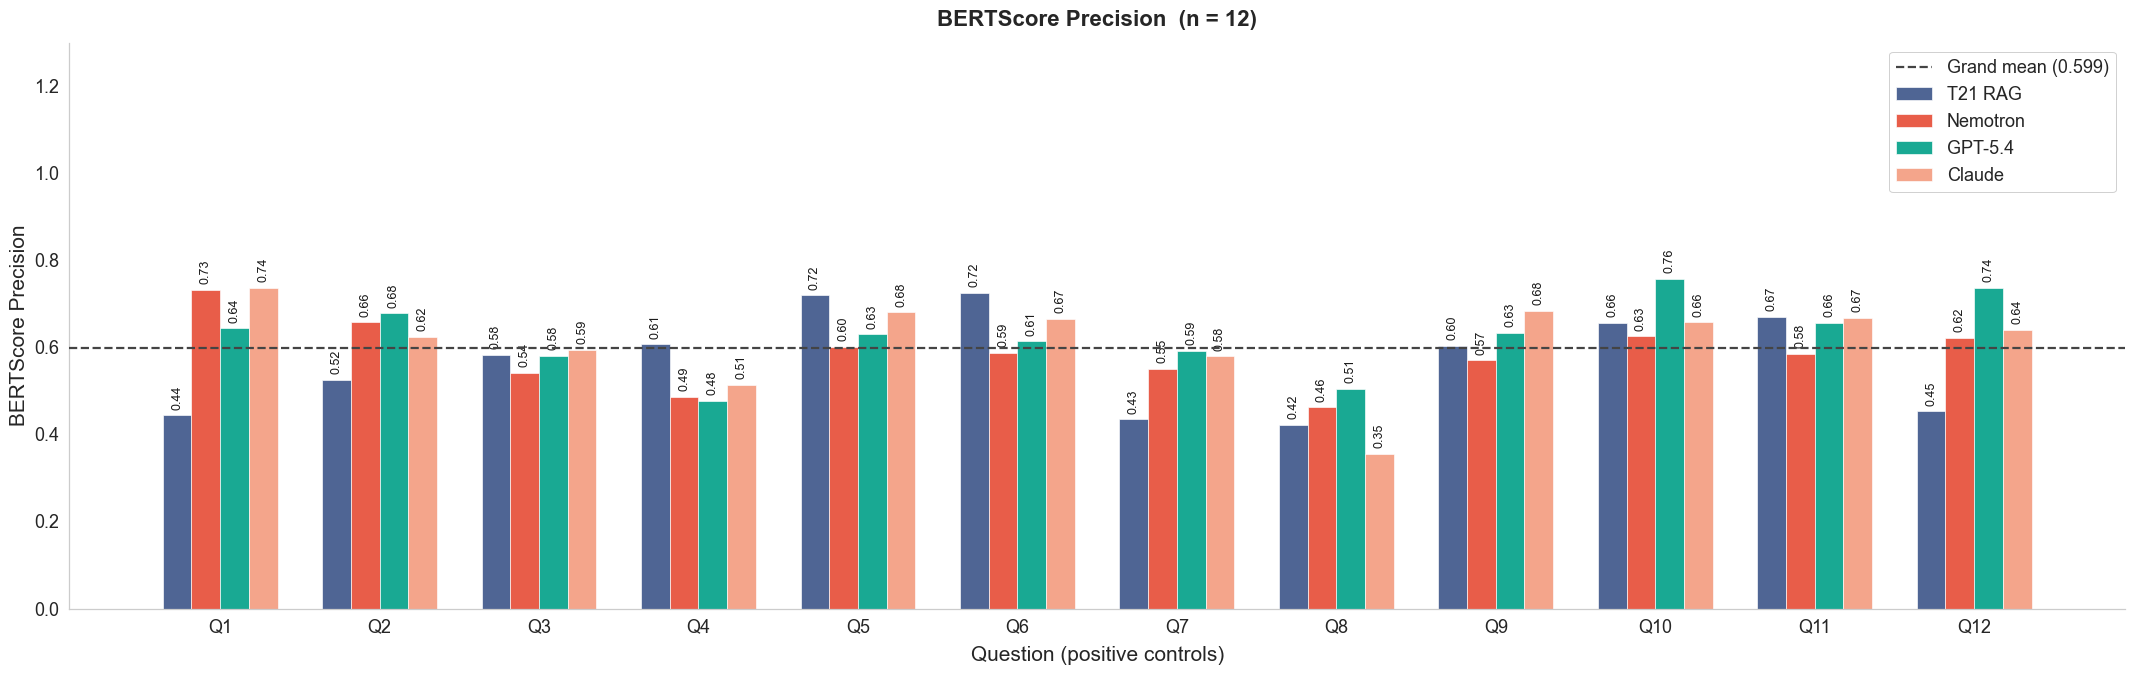

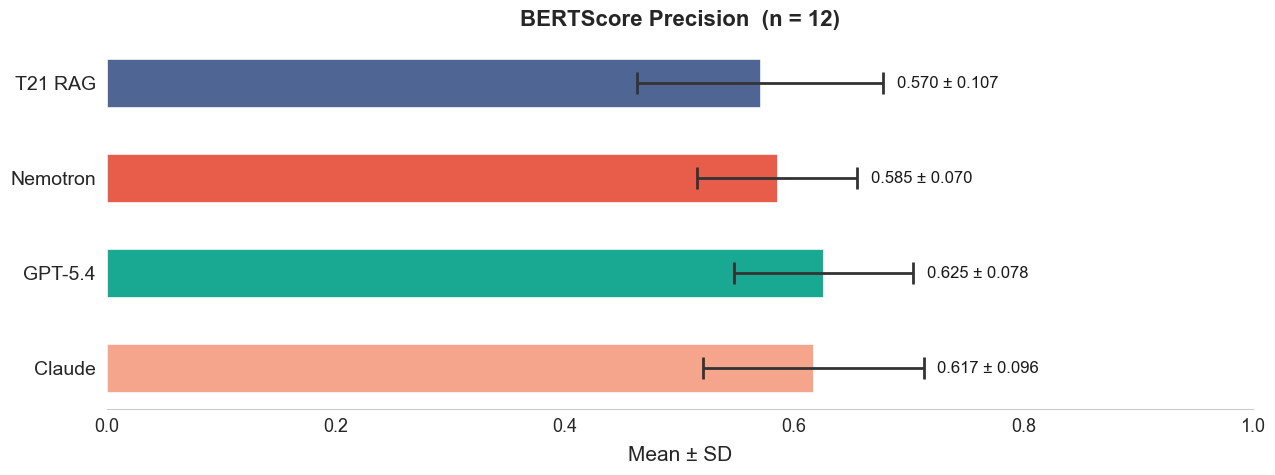

  BERTScore Precision:  T21=0.5702  Nem=0.5851  GPT=0.6253  Claude=0.6166
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=1.0000 ns  |  GPT-5.4 p=0.7002 ns  |  Claude p=0.9038 ns



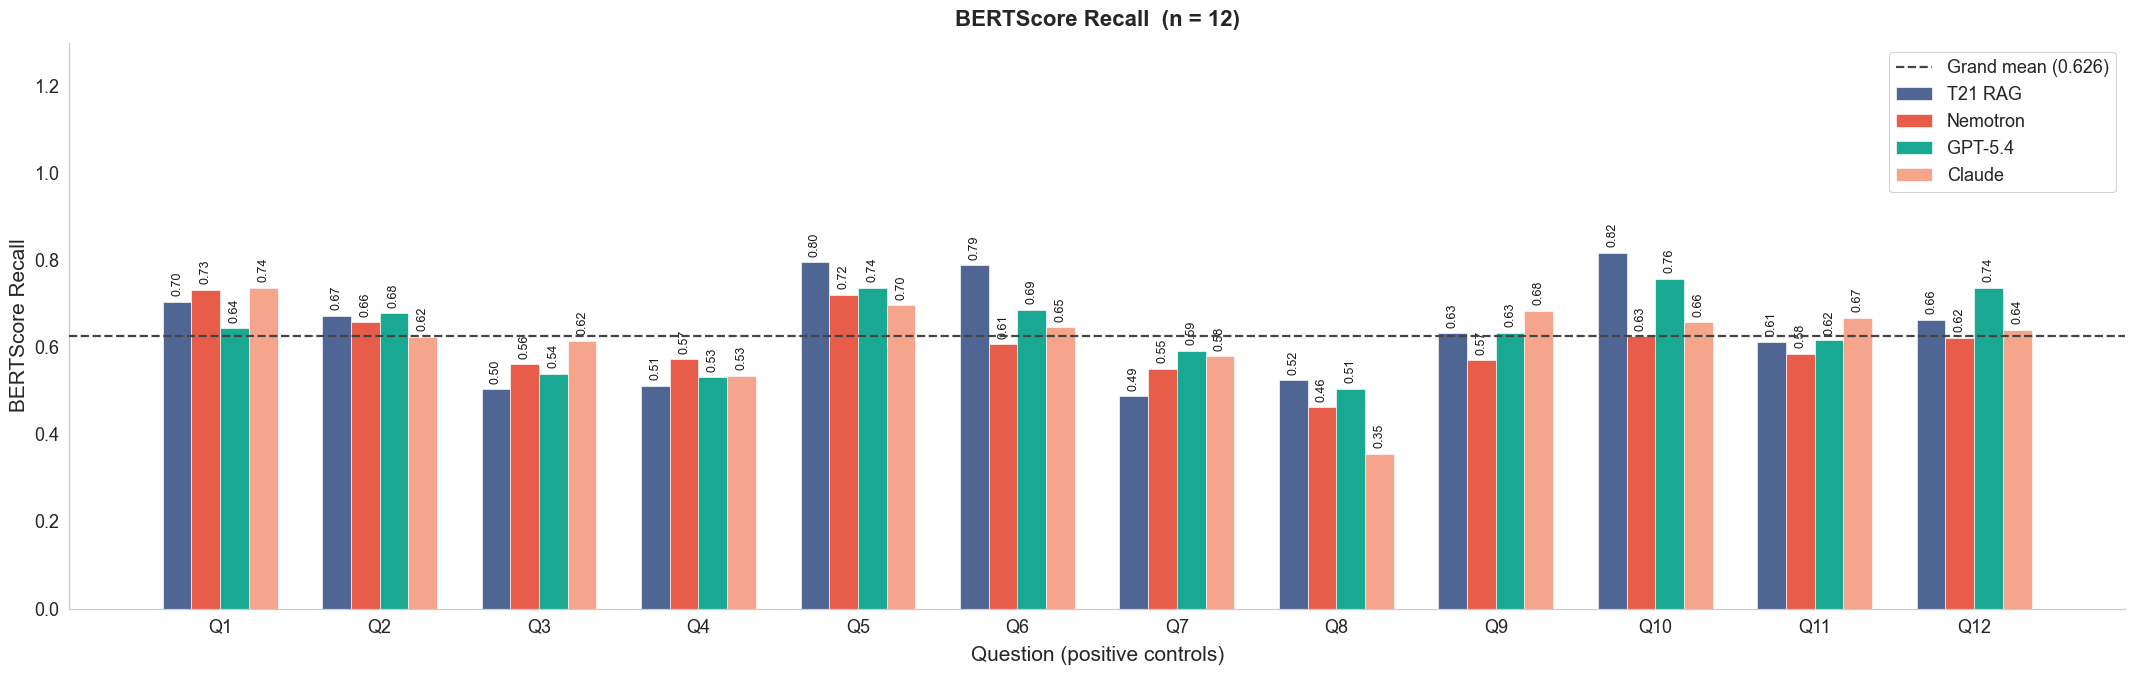

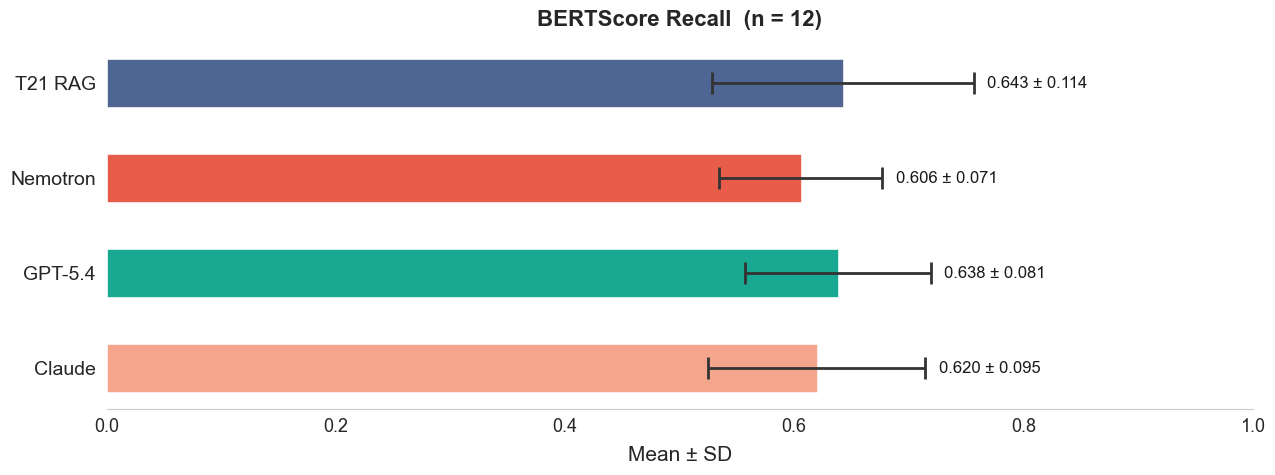

  BERTScore Recall:  T21=0.6426  Nem=0.6056  GPT=0.6380  Claude=0.6197
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=0.7002 ns  |  GPT-5.4 p=1.0000 ns  |  Claude p=1.0000 ns



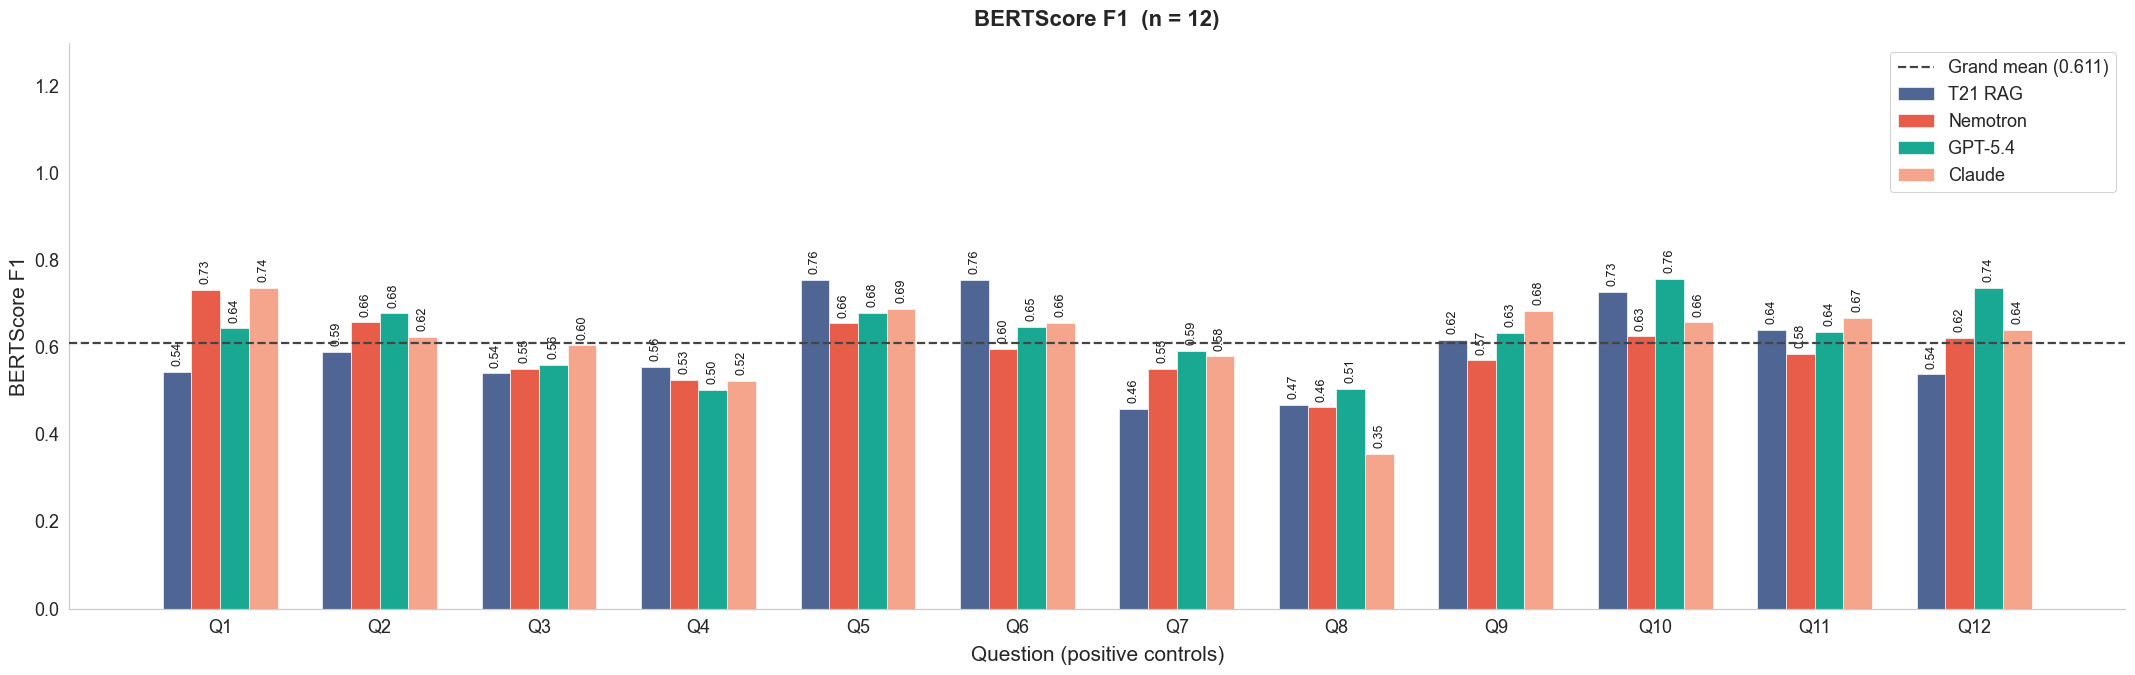

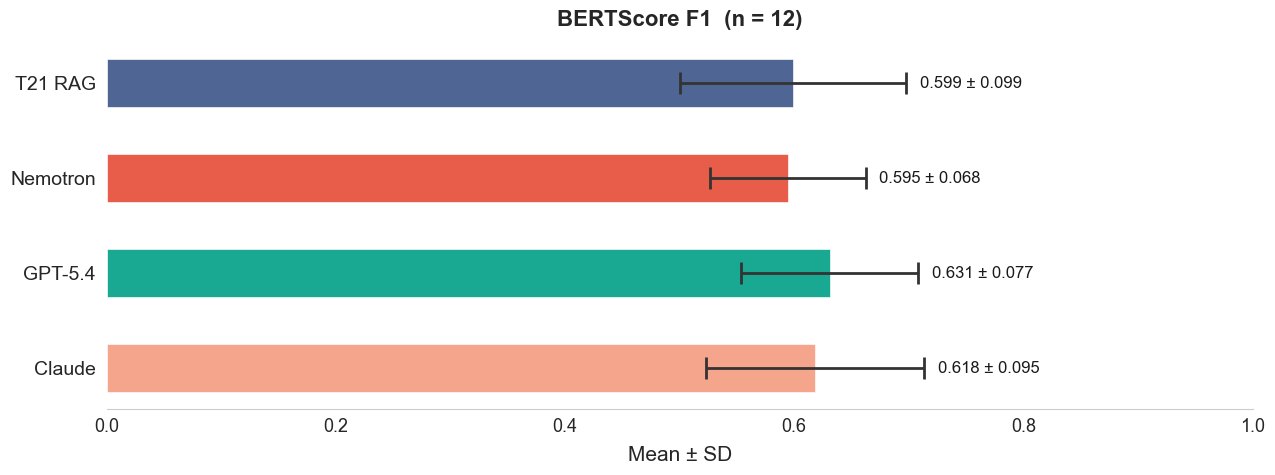

  BERTScore F1:  T21=0.5993  Nem=0.5946  GPT=0.6309  Claude=0.6181
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=1.0000 ns  |  GPT-5.4 p=0.7983 ns  |  Claude p=1.0000 ns



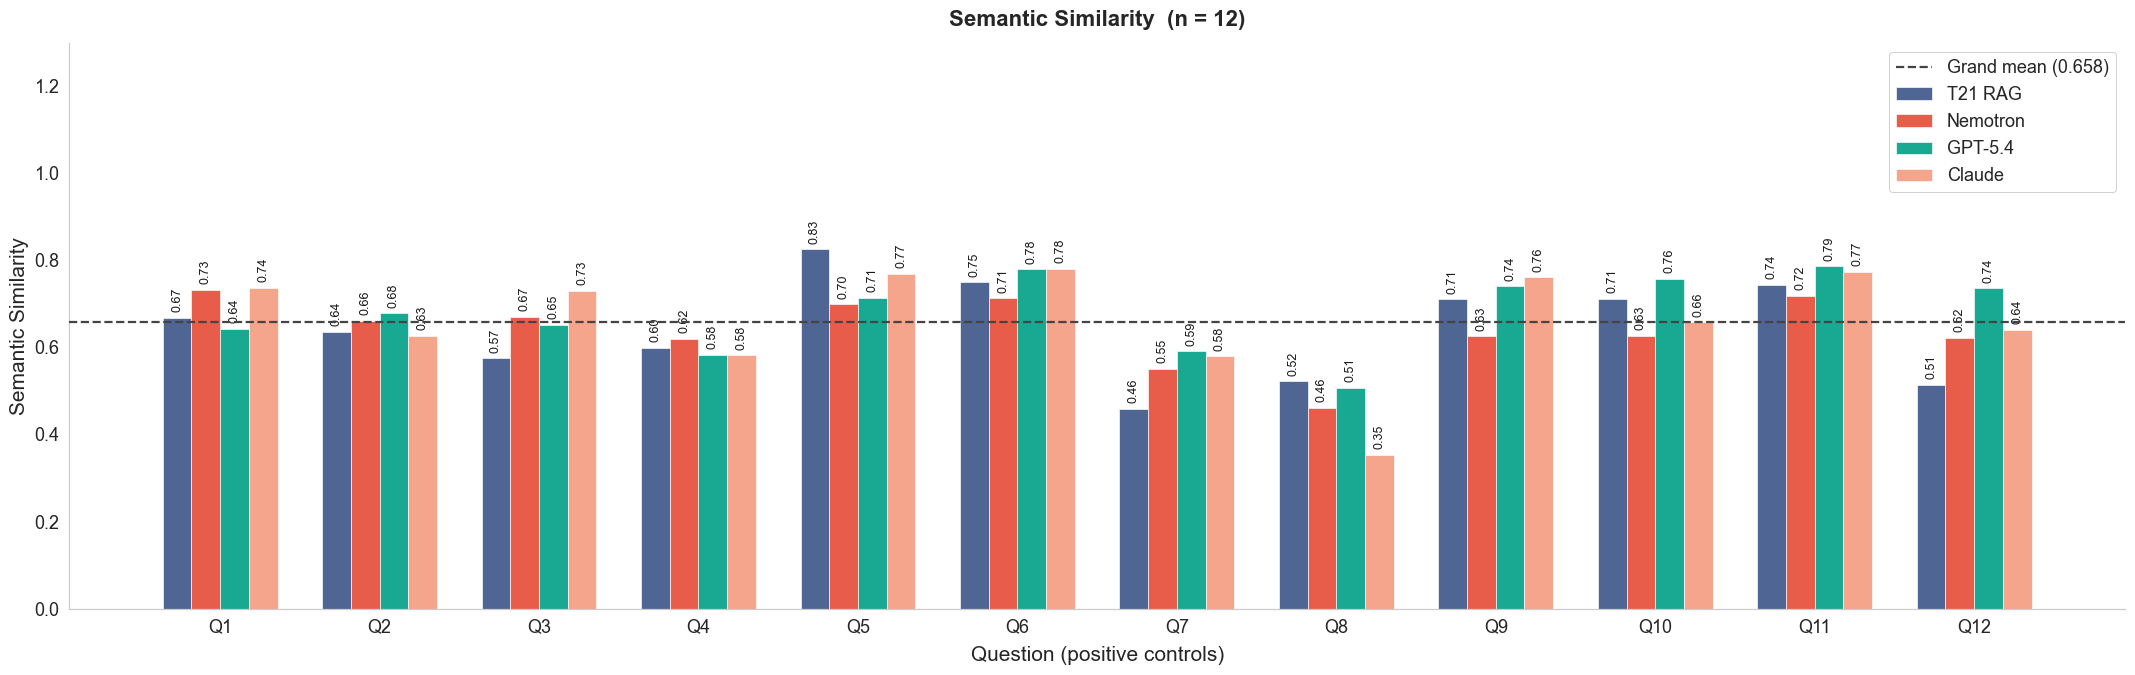

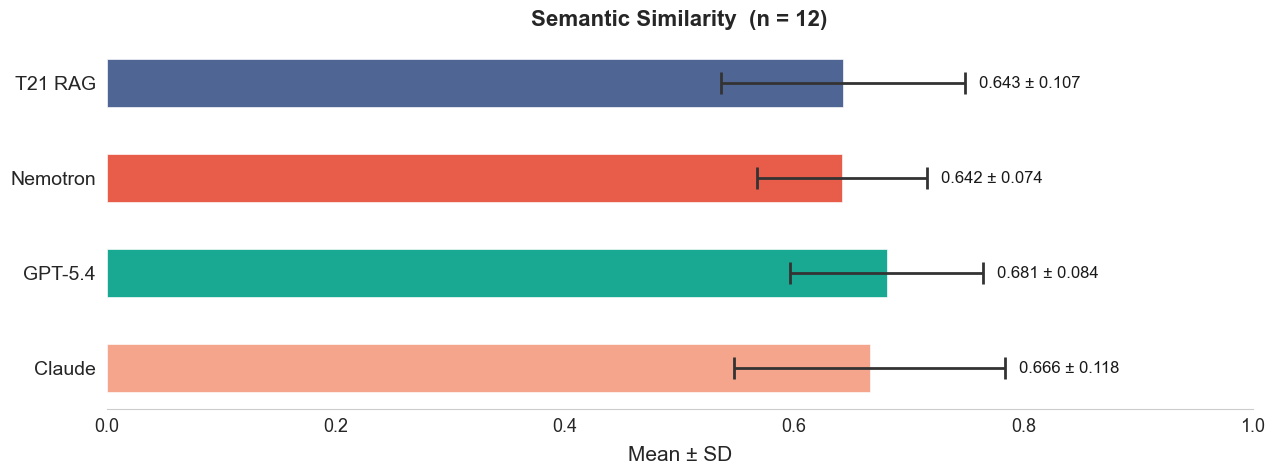

  Semantic Similarity:  T21=0.6429  Nem=0.6418  GPT=0.6807  Claude=0.6661
  Wilcoxon vs T21 (Bonferroni):  Nemotron p=1.0000 ns  |  GPT-5.4 p=0.2314 ns  |  Claude p=1.0000 ns



In [10]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import wilcoxon

# ── Nature/Science publication-quality style ───────────────────────────────────
matplotlib.rcParams.update({
    'font.family':           'sans-serif',
    'font.sans-serif':       ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':             15,
    'axes.titlesize':        16,
    'axes.labelsize':        15,
    'xtick.labelsize':       13,
    'ytick.labelsize':       13,
    'legend.fontsize':       13,
    'legend.title_fontsize': 13,
    'figure.facecolor':      'white',
    'axes.facecolor':        'white',
    'axes.spines.top':       False,
    'axes.spines.right':     False,
    'axes.grid':             False,
    'pdf.fonttype':          42,
    'ps.fonttype':           42,
})

# ── NPG (Nature Publishing Group) palette ─────────────────────────────────────
NPG_M = {
    'T21 RAG':  '#3C5488',
    'Nemotron': '#E64B35',
    'GPT-5.4':  '#00A087',
    'Claude':   '#F39B7F',
}
MODELS_M  = [('T21 RAG','t21'),('Nemotron','nemotron'),('GPT-5.4','gpt'),('Claude','claude')]
METRICS_M = [
    ('bertscore_p',  False, 'BERTScore Precision', 'bertscore_precision'),
    ('bertscore_r',  False, 'BERTScore Recall',    'bertscore_recall'),
    ('bertscore_f',  False, 'BERTScore F1',        'bertscore_f1'),
    ('semantic_sim', True,  'Semantic Similarity', 'semantic_sim'),
]

def _getv(df, mdl, key, sem):
    col = f'semantic_sim_{mdl}' if sem else f'{mdl}_{key}'
    return df[col].values if col in df.columns else np.full(len(df), np.nan)

def _sig_label(p):
    """Return stars only for significant results; None otherwise."""
    if p is None or np.isnan(p): return None
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return None

def _wilcoxon_vs_t21(ref_vals, other_vals, n_comparisons=3):
    """Paired Wilcoxon signed-rank test; returns Bonferroni-corrected p-value."""
    valid = ~(np.isnan(ref_vals) | np.isnan(other_vals))
    if valid.sum() < 5:
        return float('nan')
    if np.all(ref_vals[valid] == other_vals[valid]):
        return 1.0
    try:
        _, p = wilcoxon(ref_vals[valid], other_vals[valid])
        return min(p * n_comparisons, 1.0)
    except Exception:
        return float('nan')

pos_all = df_bench[pos_mask].reset_index(drop=True)
n_q_m   = len(pos_all)
qlbls   = [f'Q{i+1}' for i in range(n_q_m)]
n_m_m   = len(MODELS_M)
bw_m    = 0.18
boffs_m = np.linspace(-(n_m_m-1)*bw_m/2, (n_m_m-1)*bw_m/2, n_m_m)
xq_m    = np.arange(n_q_m)

# === Per-metric figures: per-question bar + summary mean±SD bar ===============
for mkey, sem, panel_title, stem in METRICS_M:
    mdata = {lbl: _getv(pos_all, mdl, mkey, sem) for lbl, mdl in MODELS_M}

    # ── Wilcoxon tests: each model vs T21 RAG (Bonferroni, 3 comparisons) ───
    ref = mdata['T21 RAG']
    pvals = {lbl: None for lbl in mdata}
    for lbl in ['Nemotron', 'GPT-5.4', 'Claude']:
        pvals[lbl] = _wilcoxon_vs_t21(ref, mdata[lbl], n_comparisons=3)

    # ── per-question bar ──────────────────────────────────────────────────────
    fg, ax = plt.subplots(figsize=(max(20, n_q_m*1.8), 7))
    for off, (lbl, _) in zip(boffs_m, MODELS_M):
        ax.bar(xq_m+off, mdata[lbl], bw_m, label=lbl, color=NPG_M[lbl],
               alpha=0.90, edgecolor='white', linewidth=0.5)
    gm_i = float(np.nanmean(np.concatenate(list(mdata.values()))))
    ax.axhline(gm_i, color='#444444', linewidth=1.6, linestyle='--', zorder=4,
               label=f'Grand mean ({gm_i:.3f})')
    for off, (lbl, _) in zip(boffs_m, MODELS_M):
        for xi, v in zip(xq_m, mdata[lbl]):
            if not np.isnan(v):
                ax.text(xi+off, v+0.013, f'{v:.2f}', ha='center', va='bottom',
                        fontsize=9, color='#1a1a1a', rotation=90)
    ax.set_xticks(xq_m); ax.set_xticklabels(qlbls, fontsize=13)
    ax.set_ylim(0, 1.30)
    ax.set_xlabel('Question (positive controls)', fontsize=15, labelpad=7)
    ax.set_ylabel(panel_title, fontsize=15)
    ax.set_title(f'{panel_title}  (n = {n_q_m})',
                 fontweight='bold', fontsize=16, pad=12)
    leg = ax.legend(loc='upper right', framealpha=0.92, fontsize=13, edgecolor='#cccccc')
    leg.get_frame().set_linewidth(0.7)
    ax.spines['left'].set_linewidth(0.9); ax.spines['bottom'].set_linewidth(0.9)
    fg.tight_layout()
    for ext in ('pdf', 'jpg', 'tiff'):
        fg.savefig(str(OUTPUT_DIR / f'{stem}_per_question.{ext}'),
                   dpi=600, bbox_inches='tight', facecolor='white')
    plt.show()

    # ── summary mean ± SD horizontal bar ─────────────────────────────────────
    fg2, ax2 = plt.subplots(figsize=(13, 5))
    lr   = [lbl for lbl, _ in reversed(MODELS_M)]   # Claude, GPT, Nemotron, T21 RAG
    mr   = [float(np.nanmean(mdata[lbl])) for lbl in lr]
    sr   = [float(np.nanstd(mdata[lbl]))  for lbl in lr]
    cr   = [NPG_M[lbl] for lbl in lr]
    yp2  = np.arange(len(lr))

    ax2.barh(yp2, mr, 0.50,
             xerr=sr,
             error_kw={'ecolor':'#333333','capsize':8,'elinewidth':2.0,'capthick':2.0},
             color=cr, alpha=0.90, edgecolor='white', linewidth=0.5)

    for yi2, lbl, v2, s2 in zip(yp2, lr, mr, sr):
        stars = _sig_label(pvals[lbl])
        label_str = f'{v2:.3f} ± {s2:.3f}   {stars}' if stars else f'{v2:.3f} ± {s2:.3f}'
        # clip_on=False so text beyond x=1.0 is not cut off
        ax2.text(v2+s2+0.012, yi2, label_str,
                 va='center', fontsize=12, color='#1a1a1a', clip_on=False)

    ax2.set_yticks(yp2); ax2.set_yticklabels(lr, fontsize=14)
    ax2.set_xlim(0.0, 1.0)
    ax2.set_xlabel('Mean ± SD', fontsize=15, labelpad=7)
    ax2.set_title(f'{panel_title}  (n = {n_q_m})',
                  fontweight='bold', fontsize=16, pad=12)
    ax2.spines['left'].set_visible(False)
    ax2.tick_params(axis='y', length=0, pad=8)
    ax2.tick_params(axis='x', labelsize=13)

    fg2.tight_layout()
    for ext in ('pdf', 'jpg', 'tiff'):
        fg2.savefig(str(OUTPUT_DIR / f'{stem}_summary.{ext}'),
                    dpi=600, bbox_inches='tight', facecolor='white')
    plt.show()

    # ── console summary ───────────────────────────────────────────────────────
    print(f'  {panel_title}:  T21={np.nanmean(mdata["T21 RAG"]):.4f}  '
          f'Nem={np.nanmean(mdata["Nemotron"]):.4f}  '
          f'GPT={np.nanmean(mdata["GPT-5.4"]):.4f}  '
          f'Claude={np.nanmean(mdata["Claude"]):.4f}')
    _p_str = '  |  '.join(
        f'{lbl} p={pvals[lbl]:.4f} {_sig_label(pvals[lbl]) or "ns"}'
        for lbl in ['Nemotron', 'GPT-5.4', 'Claude']
        if pvals[lbl] is not None and not np.isnan(pvals[lbl])
    )
    print(f'  Wilcoxon vs T21 (Bonferroni):  {_p_str}')
    print()
